# SWYNEX Task 1 — Data Cleaning & Preparation

**Dataset:** Titanic passenger dataset (public Seaborn-data GitHub repository)  
**Tools:** Python, pandas, NumPy, Matplotlib

## Objective
Inspect a raw dataset, identify missing values, duplicate rows, data types and inconsistent text values, then prepare and export a cleaned CSV.

> Run the notebook from top to bottom. It downloads the original CSV directly from the public source and saves an unchanged copy in `data/`.

## 1. Import libraries

We use:
- **pandas** to read and clean tabular data.
- **NumPy** for missing-value handling.
- **Matplotlib** for a simple data-quality chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

## 2. Download and load the public dataset

The Titanic dataset contains passenger information such as age, sex, ticket class and survival status.

In [2]:
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

raw = pd.read_csv(DATA_URL)
raw.to_csv(DATA_DIR / "titanic_raw.csv", index=False)

print("Dataset loaded successfully.")
print("Rows and columns:", raw.shape)
display(raw.head())

Dataset loaded successfully.
Rows and columns: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Initial inspection

Before changing anything, inspect the structure, column types, summary and missing values.

In [3]:
print("Dataset information:")
raw.info()

print("\nSummary:")
display(raw.describe(include="all").T)

missing_before = raw.isna().sum().sort_values(ascending=False)
print("\nMissing values by column:")
display(missing_before[missing_before > 0])

print("Exact duplicate rows:", raw.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,0
deck,688
age,177
embarked,2
embark_town,2


Exact duplicate rows: 107


## 4. Visualize missing values

The chart makes it easier to see which columns need attention.

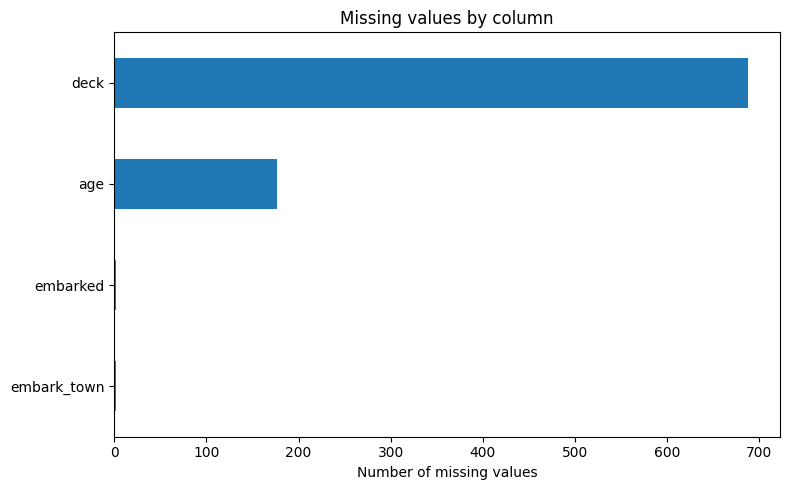

In [4]:
missing_before[missing_before > 0].sort_values().plot(
    kind="barh", figsize=(8, 5), title="Missing values by column"
)
plt.xlabel("Number of missing values")
plt.tight_layout()
plt.show()

## 5. Clean the data

Cleaning decisions:
1. Remove exact duplicate rows, if any are present.
2. Convert text columns to a consistent format (trim spaces and standardize case).
3. Fill missing `age` values with the median for the same passenger class and sex. Use the overall median only if a group has no median.
4. Fill missing `embarked` and `embark_town` with their most frequent values (mode).
5. Keep missing cabin information honestly as `Unknown`; we do not guess a cabin.
6. Convert columns to suitable data types: booleans, integers, numeric values and categories.

The code prints the duplicate count before removing rows so the action is transparent.

In [5]:
clean = raw.copy()

print("Original dataset shape:", raw.shape)
print("Working dataset shape:", clean.shape)

Original dataset shape: (891, 15)
Working dataset shape: (891, 15)


In [6]:
duplicates = clean[clean.duplicated(keep=False)]

print("Duplicate records:", len(duplicates))
display(duplicates.head(10))

Duplicate records: 160


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
42,0,3,male,NaN,0,0,7.8958,C,Third,man,True,NaN,Cherbourg,no,True
45,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
46,0,3,male,NaN,1,0,15.5000,Q,Third,man,True,NaN,Queenstown,no,False
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True


In [7]:
text_columns = clean.select_dtypes(include=["object"]).columns

for col in text_columns:
    clean[col] = clean[col].str.strip()

for col in ["sex", "who", "class", "deck", "alive", "embark_town"]:
    clean[col] = clean[col].str.lower()

clean["embarked"] = clean["embarked"].str.upper()

print("Text standardization completed!")

Text standardization completed!


In [8]:
age_group_median = clean.groupby(
    ["pclass", "sex"]
)["age"].transform("median")

clean["age"] = clean["age"].fillna(age_group_median)

clean["age"] = clean["age"].fillna(clean["age"].median())

print("Missing Age:", clean["age"].isna().sum())

Missing Age: 0


In [9]:
for col in ["embarked", "embark_town"]:

    mode_value = clean[col].mode(dropna=True)[0]

    clean[col] = clean[col].fillna(mode_value)

print("Missing Embarked:", clean["embarked"].isna().sum())
print("Missing Embark Town:", clean["embark_town"].isna().sum())

Missing Embarked: 0
Missing Embark Town: 0


In [10]:
clean["deck"] = clean["deck"].fillna("unknown")

print("Missing Deck:", clean["deck"].isna().sum())

Missing Deck: 0


In [11]:
clean["survived"] = clean["survived"].astype("bool")

clean["alive"] = clean["alive"].map({
    "yes": True,
    "no": False
}).astype("bool")

clean["adult_male"] = clean["adult_male"].astype("bool")
clean["alone"] = clean["alone"].astype("bool")

for col in ["pclass", "sibsp", "parch"]:
    clean[col] = clean[col].astype("int64")

for col in ["age", "fare"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

for col in ["sex", "embarked", "class", "who", "deck", "embark_town"]:
    clean[col] = clean[col].astype("category")

print("Data types corrected!")

Data types corrected!


In [12]:
# Remove duplicates remaining after text standardization

print("Duplicates before final removal:", clean.duplicated().sum())

clean = clean.drop_duplicates().copy()

print("Final dataset shape:", clean.shape)
print("Duplicates after removal:", clean.duplicated().sum())
print("Missing values:", clean.isna().sum().sum())

Duplicates before final removal: 113
Final dataset shape: (778, 15)
Duplicates after removal: 0
Missing values: 0


## 6. Validate the cleaned dataset

A successful cleaning pass should have no missing values in this project, no remaining exact duplicates, and appropriate data types.

In [13]:
print("Cleaned shape:", clean.shape)
print("\nMissing values after cleaning:")
display(clean.isna().sum())

print("Duplicate rows after cleaning:", clean.duplicated().sum())
print("\nFinal data types:")
display(clean.dtypes.to_frame("data_type"))

assert clean.isna().sum().sum() == 0, "There are still missing values."
assert clean.duplicated().sum() == 0, "Duplicate rows remain."

Cleaned shape: (778, 15)

Missing values after cleaning:


,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


Duplicate rows after cleaning: 0

Final data types:


,data_type
survived,bool
pclass,int64
sex,category
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,category
class,category
who,category


## 7. Export the cleaned dataset and audit summary

The cleaned CSV and a small text audit are saved in the `outputs/` folder.

In [14]:

# 1. Export cleaned dataset
clean.to_csv(OUTPUT_DIR / "titanic_cleaned.csv", index=False)

# 2. Create cleaning audit report
audit = pd.DataFrame({
    "missing_before": raw.isna().sum(),
    "missing_after": clean.isna().sum()
})

audit.to_csv(OUTPUT_DIR / "cleaning_audit.csv")

# 3. Create cleaning summary
summary = [
    f"Original shape: {raw.shape}",
    f"Cleaned shape: {clean.shape}",
    f"Exact duplicates in raw data: {raw.duplicated().sum()}",
    "Duplicates removed after text standardization: 113",
    f"Missing cells before cleaning: {int(raw.isna().sum().sum())}",
    f"Missing cells after cleaning: {int(clean.isna().sum().sum())}",
    f"Remaining duplicates: {clean.duplicated().sum()}"
]

(OUTPUT_DIR / "cleaning_summary.txt").write_text(
    "\n".join(summary),
    encoding="utf-8"
)

# 4. Display summary
print("\n".join(summary))

# 5. Confirm output files
print("\nFiles created successfully:")
print(OUTPUT_DIR / "titanic_cleaned.csv")
print(OUTPUT_DIR / "cleaning_audit.csv")
print(OUTPUT_DIR / "cleaning_summary.txt")


Original shape: (891, 15)
Cleaned shape: (778, 15)
Exact duplicates in raw data: 107
Duplicates removed after text standardization: 113
Missing cells before cleaning: 869
Missing cells after cleaning: 0
Remaining duplicates: 0

Files created successfully:
outputs/titanic_cleaned.csv
outputs/cleaning_audit.csv
outputs/cleaning_summary.txt


## 8. Conclusion

The raw Titanic passenger data was inspected and cleaned. Missing numeric values were imputed using a documented median strategy, missing categorical values were handled using mode or an explicit `unknown` category, exact duplicates were removed if present, text values were standardized, and data types were corrected.

**Important:** A duplicate count of zero is a valid finding. Do not invent duplicate records just to claim they were removed.